# Relativistic shock: baseline plots

Follow the school workflow: **Pencil reader → Matplotlib plot**.

This notebook uses the small files copied from Vera: `time_series.dat`, `yzaverages_final.dat`, and the dimension/parameter metadata. It plots time histories and the final physical velocity and energy-density profiles. The extracted averages contain only one saved time, so they do not support a time-evolution heatmap.

This is the standard baseline. Later comparisons with KT and adaptive methods will use matched times and resolution and a suitable reference. These plots alone do not establish excessive damping.

Select the project's `.venv` kernel and run the cells in order.

## 1. Import Pencil and locate the run

The quick-start guide makes Pencil's Python directory available by sourcing `sourceme.sh`. A VS Code kernel launched separately does not inherit that shell change; the path below makes the existing local Pencil checkout available to this kernel. It does not download another package.

In [4]:
from pathlib import Path
import sys

pencil_python = Path.home() / "Work/research/software/pencil-code/python"
sys.path.insert(0, str(pencil_python))

import pencil as pc
import numpy as np
import matplotlib.pyplot as plt

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / ".git").exists() and (p / "runs").is_dir())
run = root / "runs/relshock-standard"
datadir = str(run / "data")
print("Pencil:", pc.__file__)
print("Data:", datadir)

Pencil: /Users/chrischoi/Work/research/software/pencil-code/python/pencil/__init__.py
Data: /Users/chrischoi/Work/grad/workshops/KAAI_alberto/KAAI_projects/runs/relshock-standard/data


## 2. Time evolution: `pc.read.ts`

`urms` shows the RMS physical speed. `ekin` is this run's relativistic kinetic-energy diagnostic. For this nonmagnetic radiation fluid, `ekin + rhom` gives the corresponding mean lab-frame energy diagnostic.

The initial pressure imbalance accelerates the fluid; rising kinetic energy is expected in this shock tube. Boundary fluxes and explicit dissipation must be considered when interpreting energy changes. This run uses `ENTROPY=noentropy`, so the sound-wave notebook's `ekin + ethm` expression is not applicable.

The time-series columns are rounded text output. Very small fluctuations in their sum are not a precise measure of energy-conservation error.

In [5]:
ts = pc.read.ts(datadir=datadir, quiet=True)
print("Available diagnostics:", ts.keys)
print(f"{len(ts.t)} records; t = {ts.t[0]:g} to {ts.t[-1]:g}")

Available diagnostics: ['it', 't', 'dt', 'urms', 'ekin', 'ethm', 'ruxm', 'rhom']
301 records; t = 0 to 3


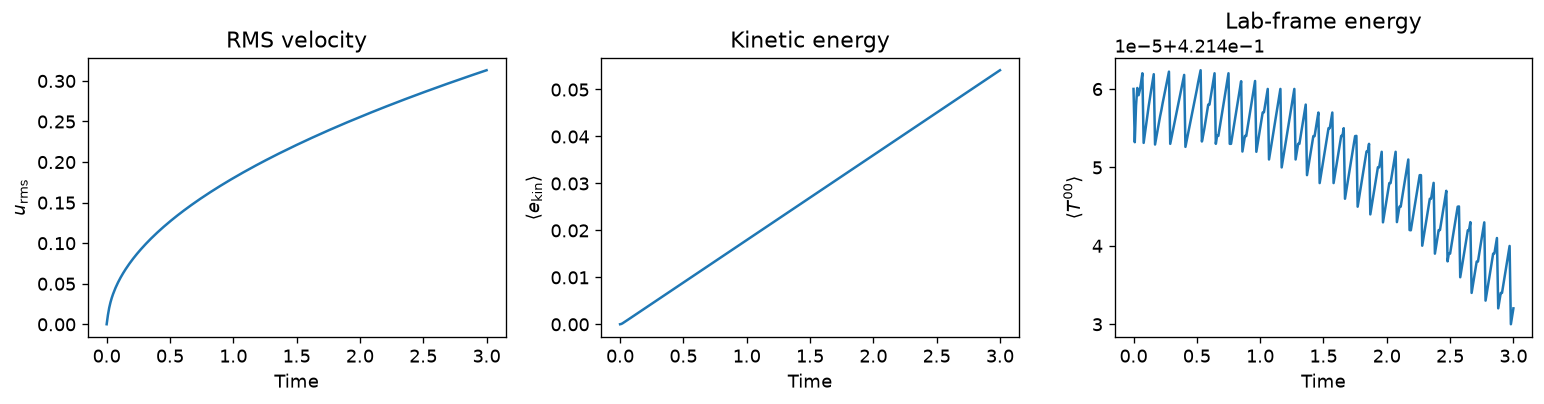

In [6]:
fig_ts, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].plot(ts.t, ts.urms)
axes[0].set_ylabel(r"$u_{\rm rms}$")
axes[0].set_title("RMS velocity")
axes[1].plot(ts.t, ts.ekin)
axes[1].set_ylabel(r"$\langle e_{\rm kin}\rangle$")
axes[1].set_title("Kinetic energy")
axes[2].plot(ts.t, ts.ekin + ts.rhom)
axes[2].set_ylabel(r"$\langle T^{00}\rangle$")
axes[2].set_title("Lab-frame energy")
for ax in axes:
    ax.set_xlabel("Time")
fig_ts.tight_layout()
plt.show()

## 3. Final spatial profiles: `pc.read.aver`

`yzaver.in` requests `uxmx` and `rhomx`. Pencil computes these averages from the physical velocity and fluid-frame energy density. Since `ny = nz = 1`, averaging over those directions preserves the full profiles along x. No conservative-to-primitive conversion is needed for these averaged quantities.

The selected file holds one complete output record. We use the saved time from that record. The coordinate array is reconstructed from the saved domain and resolution; this run has an unshifted, uniform, nonperiodic x grid, which includes both endpoints.

In [ ]:
aver = pc.read.aver(
    datadir=datadir,
    simdir=str(run),
    plane_list=["yz"],
    avfile_list=["yzaverages_final.dat"],
    infile_list=["yzaver.in"],
    quiet=True,
)
par = pc.read.param(datadir=datadir, quiet=True)
dim = pc.read.dim(datadir=datadir)
assert dim.ny == dim.nz == 1, "These profiles assume a 1D run."
assert par.lequidist[0] and not par.lperi[0], "Expected a uniform, nonperiodic x grid."
assert not par.lshift_origin[0] and not par.lshift_origin_lower[0], "Expected an unshifted grid."
x = np.linspace(par.xyz0[0], par.xyz1[0], dim.nx)
t_final = float(aver.yz.t[-1])
vx = aver.yz.uxmx[-1]
e = aver.yz.rhomx[-1]
assert vx.shape == e.shape == x.shape
print(f"Final saved profiles: t = {t_final:g}, {len(x)} grid points")

In [ ]:
fig_profiles, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x, e)
axes[0].set_ylabel(r"Fluid-frame energy density $e$")
axes[0].set_title("Energy density")
axes[1].plot(x, vx)
axes[1].set_ylabel(r"Physical velocity $v_x/c$")
axes[1].set_title("Velocity")
for ax in axes:
    ax.set_xlabel("Position x")
fig_profiles.suptitle(f"Standard baseline, t = {t_final:g}")
fig_profiles.tight_layout()
plt.show()

Look for the moving shock, the smooth rarefaction, and the regions between them. In future comparisons, inspect shock location, smearing, and oscillations at matched times. This run includes explicit viscosity and density diffusion, and its initial jump was smoothed; an inviscid discontinuous Riemann solution is not an identical problem.

Pressure follows `p = cs0**2 * e`, so its profile is a rescaled energy-density profile for this equation of state.

## Optional: save the figures

Generated figures go in the run's ignored `plots` directory.

In [ ]:
out = run / "plots"
out.mkdir(exist_ok=True)
fig_ts.savefig(out / "timeseries.png", dpi=200, bbox_inches="tight")
fig_profiles.savefig(out / "final_profiles.png", dpi=200, bbox_inches="tight")
print("Figures saved in:", out)